In [49]:
import pandas as pd

In [50]:
def load_events(path):
    with open(path) as f:
        lines = f.readlines()

    event_header_idx = next(
        i for i, line in enumerate(lines)
        if line.startswith('#') and 'run' in line and 'event' in line
        )
    end_idx = next(
        i for i, line in enumerate(lines[event_header_idx+1:], start=event_header_idx+1) 
        if line.startswith('#')
        )

    rows = [line.split() for line in lines[event_header_idx+1:end_idx] if line.strip()]
    cols = ['run', 'event', 'subevent', 'MJD', 'logE', 'AngErr', 'RA', 'Dec', 'Azimuth', 'Zenith']
    df = pd.DataFrame(rows, columns=cols).astype(float)
    return df 

In [51]:
df = load_events('/Users/luisrojascastillo/Downloads/icecube_public.csv')
print(df.shape)
df.head()

(129840, 10)


,run,event,subevent,MJD,logE,AngErr,RA,Dec,Azimuth,Zenith
0,134064.0,1387134.0,0.0,58977.232779,2.82,2.02,21.836,17.219,18.211,107.324
1,134064.0,3785767.0,0.0,58977.243173,2.98,1.10,144.544,6.513,259.254,96.423
2,134064.0,4626685.0,0.0,58977.246818,3.99,0.20,81.040,-13.347,324.113,76.673
3,134064.0,4654824.0,0.0,58977.246939,4.77,0.20,101.719,-60.054,303.647,29.924
4,134064.0,5351698.0,0.0,58977.249959,5.03,0.20,176.935,-63.203,229.336,26.680


These are the steps for the marginal probability density function for log10(E/GeV)

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

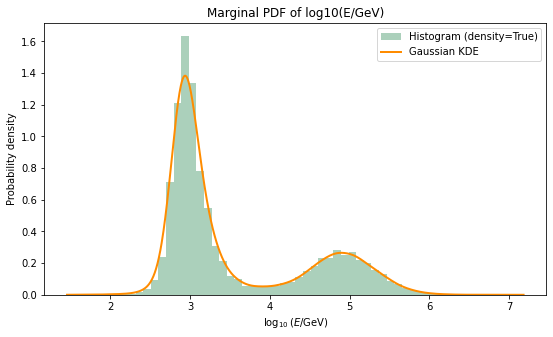

In [5]:
logE = df['logE'].values

fig, ax = plt.subplots(figsize=(9,5))

# Histogram density
ax.hist(logE, bins=60, density=True, alpha=0.4, color='seagreen', label='Histogram (density=True)')

# KDE
kde = gaussian_kde(logE)
grid = np.linspace(logE.min(), logE.max(), 1000)
ax.plot(grid, kde(grid), color='darkorange', lw=2, label='Gaussian KDE')

ax.set_xlabel(r'$\log_{10} (E/\mathrm{GeV})$')
ax.set_ylabel('Probability density')
ax.set_title('Marginal PDF of log10(E/GeV)')
ax.legend()

This is for the marginal PDF for the right ascension

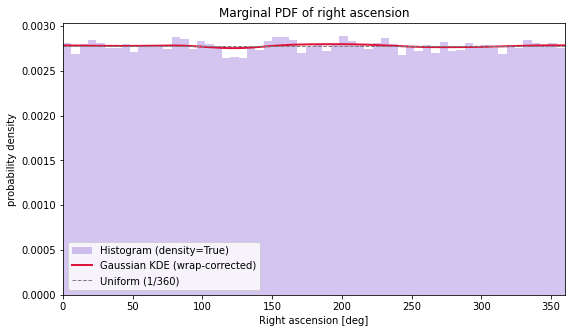

In [6]:
ra = df['RA'].values # degrees ranging from 0 to 360 (full circle)

fig, ax = plt.subplots(figsize=(9,5))

ax.hist(ra, bins=60, range=(0,360), density=True, alpha=0.4, color='mediumpurple', label='Histogram (density=True)')
ra_padded = np.concatenate([ra - 360, ra , ra + 360])
kde = gaussian_kde(ra_padded)

grid = np.linspace(0, 360, 1000)
pdf_vals = kde(grid)*3
ax.plot(grid, pdf_vals, color='crimson', lw=2, label='Gaussian KDE (wrap-corrected)')

ax.axhline(1/360, color='gray', ls='--', lw=1, label='Uniform (1/360)')
ax.set_xlabel('Right ascension [deg]')
ax.set_ylabel('probability density')
ax.set_xlim(0,360)
ax.set_title('Marginal PDF of right ascension')
ax.legend()

This is the marginal PDF for the sin(declination)

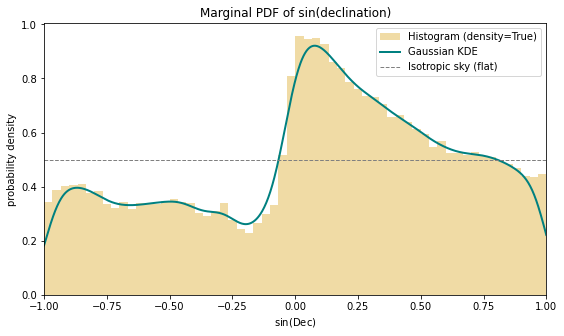

In [7]:
sindec = np.sin(np.radians(df['Dec'].values)) # converts Dec[deg] -> sin(Dec)

fig, ax = plt.subplots(figsize=(9,5))

# Histogram density
ax.hist(sindec, bins=60, range=(-1,1), density=True, alpha=0.4, color='goldenrod', 
        label='Histogram (density=True)'
)

# KDE (bounded domain [-1, 1]; no wraparound needed)
kde = gaussian_kde(sindec)
grid = np.linspace(-1, 1, 1000)
ax.plot(grid, kde(grid), color='teal', lw=2, label='Gaussian KDE')

# Reference to the uniform-over-the-sky expectation
ax.axhline(0.5, color='gray', ls='--', lw=1, label='Isotropic sky (flat)')

ax.set_xlabel(r'$\sin(\mathrm{Dec})$')
ax.set_ylabel('probability density')
ax.set_xlim(-1,1)
ax.set_title('Marginal PDF of sin(declination)')
ax.legend()

I had actually forgotten about the marginal PDF of the time, so I just filled it in after I had, unfortunately, completed the entire project.

n=129840 MJD range: 58977.233 to 59361.819 (384.6 days)


(0.0015, 0.0035)

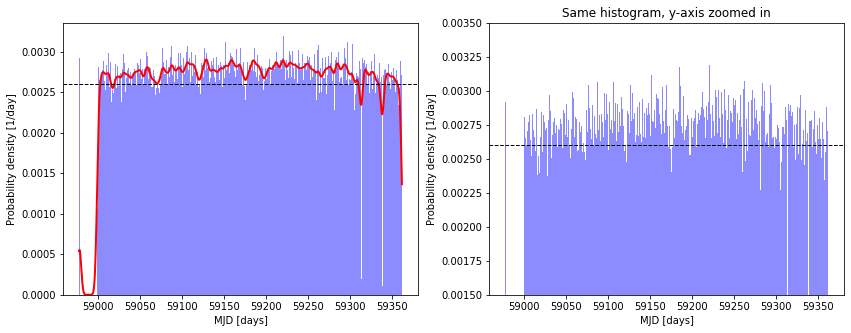

In [56]:
t = df['MJD'].values
tmin, tmax = t.min(), t.max()
print(f"n={len(t)} MJD range: {tmin:.3f} to {tmax:.3f} ({tmax-tmin:.1f} days)")

fig, axes = plt.subplots(1, 2,figsize=(14,5))

ax = axes[0]
nbins=int(np.ceil(tmax - tmin))
ax.hist(t, bins=nbins, density=True, alpha=0.45, color='blue', label=f'Hisotgram (~1 day bins, {nbins} bins)')
grid = np.linspace(tmin, tmax, 1500)
ax.plot(grid, gaussian_kde(t, bw_method=0.02)(grid), color='red', lw=2, label='Gaussian KDE (bw factor of 0.02)')
ax.axhline(1/(tmax - tmin), color='k', ls='--', lw=1, label='Uniform over observed span')
ax.set_xlabel('MJD [days]')
ax.set_ylabel('Probability density [1/day]')

ax = axes[1]
ax.hist(t, bins=nbins, density=True, alpha=0.45, color='blue')
ax.axhline(1/(tmax-tmin), color='k', ls='--', lw=1)
ax.set_xlabel('MJD [days]')
ax.set_ylabel('Probability density [1/day]')
ax.set_title('Same histogram, y-axis zoomed in')
ax.set_ylim(0.0015, 0.0035)

This is the marginal CDF of log10(E/GeV)

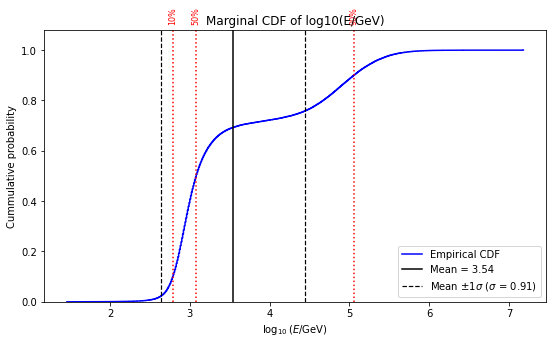

In [11]:
logE = df['logE'].values
n = len(logE)

# Empirical CDF
x_sorted = np.sort(logE)
cdf = np.arange(1, n+1)/n 

# Quantiles
q_10, q_50, q_90 = np.percentile(logE, [10, 50, 90])

# Mean and standard deviation
mean = np.mean(logE)
std = np.std(logE)

fig, ax = plt.subplots(figsize=(9,5))

# Step function for the empirical CDF
ax.step(x_sorted, cdf, where='post', color='blue', lw=1.5, label='Empirical CDF')

# Qnautile lines are dotted
for q, val, lbl in [(10, q_10, '10%'), (50, q_50, '50%'), (90, q_90, '90%')]:
    ax.axvline(val, color='red', ls=':', lw=1.5)
    ax.text(val, 1.02, lbl, rotation=90, va='bottom', ha='center', 
            color= 'red', fontsize=8, transform=ax.get_xaxis_transform())

# Mean  is a solid line
ax.axvline(mean, color='black', ls='-', lw=1.5, label=f'Mean = {mean:.2f}')

# Mean +/- 1 standard deviation as dashed lines
ax.axvline(mean - std, color='black', ls='--', lw=1.2, label=f'Mean $\pm 1\sigma$ ($\sigma$ = {std:.2f})')
ax.axvline(mean + std, color='black', ls='--', lw=1.2)

ax.set_xlabel(r'$\log_{10}(E/\mathrm{GeV})$')
ax.set_ylabel('Cummulative probability')
ax.set_ylim(0, 1.08)
ax.set_title('Marginal CDF of log10(E/GeV)')
ax.legend(loc='lower right')

This is the marginal PDF of the time difference between consecutive events for all positive time differences and for time differences less than 1000 seconds that are positive.

In [13]:
from scipy.stats import kstest, expon

In [15]:
mjd = df['MJD'].values # not resorted

dt_days = np.diff(mjd) # dt[i] = MJD[i+1] - MJD[i]
dt_sec = dt_days * 86400.0

n_total = len(dt_sec)
n_negative = np.sum(dt_sec <= 0)
dt_pos = dt_sec[dt_sec > 0] # drops non-positive

print(f"Total consecutive pairs: {n_total}")
print(f"Non-positive (dropped): {n_negative}")
print(f"Positive dt remaining: {len(dt_pos)}")
print(f"dt range (positive): {dt_pos.min():.4g} s to {dt_pos.max():.4g} s")
print(f"mean dt = {dt_pos.mean():.3f} s -> rate = {1/dt_pos.mean():.5f} events/s")


Total consecutive pairs: 129839
Non-positive (dropped): 6
Positive dt remaining: 129833
dt range (positive): 0.002592 s to 1.781e+06 s
mean dt = 255.931 s -> rate = 0.00391 events/s



Ks test (a) full positive dt vs Exp($\lambda$=0.003907): D=0.0228, p=3.22e-59
KS test (b) dt < 1000s vs Exp($\lambda$=0.003907): D=0.0344, p=9.39e-132

Fraction of positive dt >= 1000 s: 0.0157


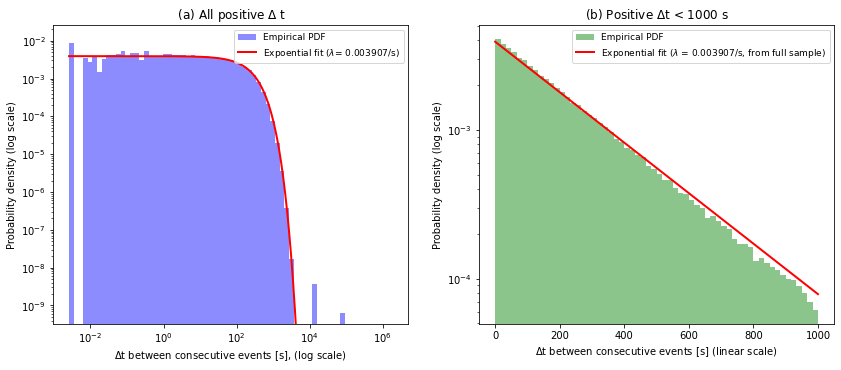

In [25]:
rate_full = 1.0 / dt_pos.mean()
fig, axes = plt.subplots(1, 2, figsize=(14,5.5))

ax = axes[0]
log_bins = np.logspace(np.log10(dt_pos.min()), np.log10(dt_pos.max()), 70)
ax.hist(dt_pos, bins=log_bins, density=True, alpha=0.45, color='blue', label='Empirical PDF')

xg = np.logspace(np.log10(dt_pos.min()), np.log10(dt_pos.max()), 1000)
ax.plot(xg, rate_full * np.exp(-rate_full * xg), color='red', lw=2, label=f'Expoential fit ($\lambda$= {rate_full:.4g}/s)')

ax.set_xscale('log')
ax.set_yscale('log')
hist_vals, _ = np.histogram(dt_pos, bins=log_bins, density=True)
ymin = hist_vals[hist_vals > 0].min()
ax.set_ylim(bottom=ymin * 0.5, top=hist_vals.max() * 3)
ax.set_xlabel('$\Delta$t between consecutive events [s], (log scale)')
ax.set_ylabel('Probability density (log scale)')
ax.set_title(' (a) All positive $\Delta$ t')
ax.legend(fontsize=9)

dt_sub = dt_pos[dt_pos < 1000]
rate_sub = 1.0/dt_sub.mean() # local estimate

ax = axes[1]
ax.hist(dt_sub, bins=60, range=(0,1000), density=True, alpha=0.45, color='green', label='Empirical PDF')

xg2 = np.linspace(0, 1000, 1000)
ax.plot(xg2, rate_full * np.exp(-rate_full * xg2), color='red', lw=2, label=f'Exponential fit ($\lambda$ = {rate_full:.4g}/s, from full sample)')

ax.set_yscale('log')
ax.set_xlabel('$\Delta$t between consecutive events [s] (linear scale)')
ax.set_ylabel('Probability density (log scale)')
ax.set_title('(b) Positive $\Delta$t < 1000 s')
ax.legend(fontsize=9)

# Goodness of fit check: Kolmogorov-Smirnov test vs the exponential
ks_full = kstest(dt_pos, 'expon', args=(0,1/rate_full))
ks_sub = kstest(dt_sub, 'expon', args=(0,1/rate_full))
print(f"\nKs test (a) full positive dt vs Exp($\lambda$={rate_full:.4g}): D={ks_full.statistic:.4f}, p={ks_full.pvalue:.3g}")
print(f"KS test (b) dt < 1000s vs Exp($\lambda$={rate_full:.4g}): D={ks_sub.statistic:.4f}, p={ks_sub.pvalue:.3g}")

# What fraction of the full sample is >= 1000 s?
frac_ge_1000 = np.mean(dt_pos >= 1000)
print(f"\nFraction of positive dt >= 1000 s: {frac_ge_1000:.4f}")

This is the joint PDF of sin(declination) vs log10(E/GeV)

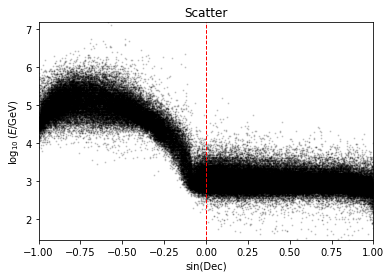

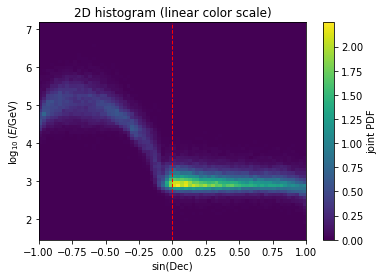

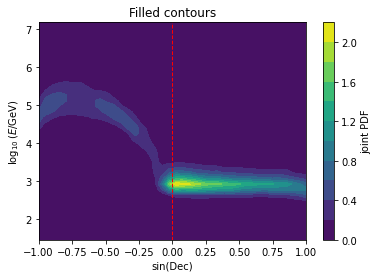

In [30]:
# Scatter plot
plt.scatter(sindec, logE, s=1, marker='o', c='k', alpha=0.15)
plt.xlabel('sin(Dec)')
plt.ylabel(r'$\log_{10}(E/\mathrm{GeV})$')
plt.xlim(-1.,1.)
plt.ylim(logE.min(), logE.max())
plt.axvline(0, color='red', ls='--', lw=1)
plt.title('Scatter')
plt.show()

# 2D histogram
Nbins = 70 
_, _, _, image = plt.hist2d(sindec, logE, bins=Nbins, range=[[-1.,1.], [logE.min(), logE.max()]], density=True)
cbar = plt.colorbar(image, label='joint PDF')
plt.xlabel('sin(Dec)')
plt.ylabel(r'$\log_{10}(E/\mathrm{GeV})$')
plt.axvline(0, color='red', ls='--', lw=1)
plt.title('2D histogram (linear color scale)')
plt.show()

Nbins = 40 # this is to reduce an overuse of binning

# contours
x = np.linspace(-1., 1., Nbins)
y = np.linspace(logE.min(), logE.max(), Nbins)
X, Y = np.meshgrid(x, y)
z,_,_ = np.histogram2d(sindec, logE, bins=Nbins, range=[[-1.,1.], [logE.min(), logE.max()]], density=True)
cs = plt.contourf(X, Y, z.T, levels=10)
cbar = plt.colorbar(cs, label='joint PDF')
plt.xlabel('sin(Dec)')
plt.ylabel(r'$\log_{10}(E/\mathrm{GeV})$')
plt.axvline(0, color='red', ls='--', lw=1)
plt.title('Filled contours')
plt.show()

The scatter plot of Dec vs RA using a fake dataset with only a handful of events

Text(0.5, 1.0, 'check: Known RA/Dec points on Mollweide grid')

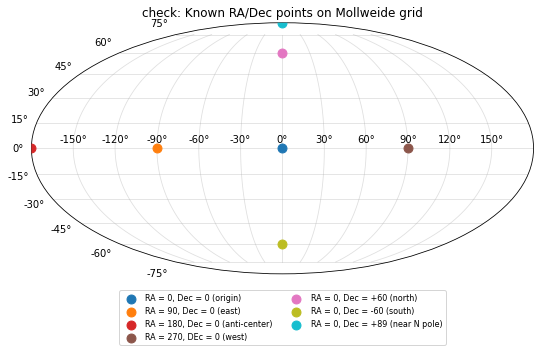

In [33]:
def radec_to_mollweide_coords(ra_deg, dec_dag):
    ra = np.asarray(ra_deg, dtype=float)
    dec = np.asarray(dec_dag, dtype=float)
    ra_shifted = np.where(ra > 180, ra - 360, ra)
    lon = -np.radians(ra_shifted)
    lat = np.radians(dec)
    return lon, lat

test_points = {
    'RA = 0, Dec = 0 (origin)': (0, 0),
    'RA = 90, Dec = 0 (east)': (90, 0),
    'RA = 180, Dec = 0 (anti-center)': (180, 0),
    'RA = 270, DEc = 0 (west)': (270, 0),
    'RA = 0, Dec = +60 (north)': (0, 60), 
    'RA = 0, Dec = -60 (south)': (0, -60),
    'RA = 0, Dec = +89 (near N pole)': (0, 89),
}

fig = plt.figure(figsize=(9,5))
ax = fig.add_subplot(111, projection='mollweide')
ax.grid(True, alpha=0.4)

colors = plt.cm.tab10(np.linspace(0, 1, len(test_points)))
for (label, (ra, dec)), c in zip(test_points.items(), colors):
    lon, lat = radec_to_mollweide_coords(ra, dec)
    ax.scatter(lon, lat, s=80, color=c, label=label, zorder=5)

ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.05), fontsize=8, ncol=2)
ax.set_title('check: Known RA/Dec points on Mollweide grid')

Now this is the Mollweide projection for the full dataset

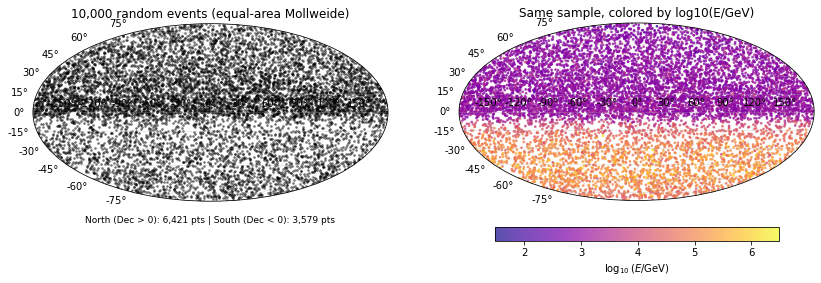

In [35]:
def radec_to_mollweide_coords(ra_deg, dec_deg):
    ra = np.asarray(ra_deg, dtype=float)
    dec = np.asarray(dec_deg, dtype=float)
    ra_shifted = np.where(ra > 180, ra - 360, ra)
    lon = -np.radians(ra_shifted)
    lat = np.radians(dec)
    return lon, lat

# this is the subsample for ~10,000 events for a reasonable scatter
rng = np.random.default_rng(42)
N_SAMPLE = 10_000
idx = rng.choice(len(df), size=N_SAMPLE, replace=False)
sample = df.iloc[idx]

lon, lat = radec_to_mollweide_coords(sample['RA'].values, sample['Dec'].values)
logE = sample['logE'].values

fig = plt.figure(figsize=(14,6))

# plain scatter
ax1 = fig.add_subplot(121, projection='mollweide')
ax1.scatter(lon, lat, s=3, c='k', alpha=0.4)
ax1.grid(True, alpha=0.3)
ax1.set_title(f'{N_SAMPLE:,} random events (equal-area Mollweide)')
n_north = np.sum(sample['Dec'].values > 0)
n_south = np.sum(sample['Dec'].values < 0)
ax1.text(0.5, -0.12, f'North (Dec > 0): {n_north:,} pts | South (Dec < 0): {n_south:,} pts', transform=ax1.transAxes, ha='center', fontsize=9)

# colored by energy or spectral symmetry
ax2 = fig.add_subplot(122, projection='mollweide')
sc = ax2.scatter(lon ,lat, s=3, c=logE, cmap='plasma', alpha=0.7, vmin=logE.min(), vmax=logE.max())
ax2.grid(True, alpha=0.3)
ax2.set_title('Same sample, colored by log10(E/GeV)')
cbar = fig.colorbar(sc, ax=ax2, orientation='horizontal', pad=0.08, shrink=0.8)
cbar.set_label(r'$\log_{10}(E/\mathrm{GeV})$')

This is the joint PDf of sin(declination) vs RA (right ascension)

Text(0.5, 1.0, 'Filled contours')

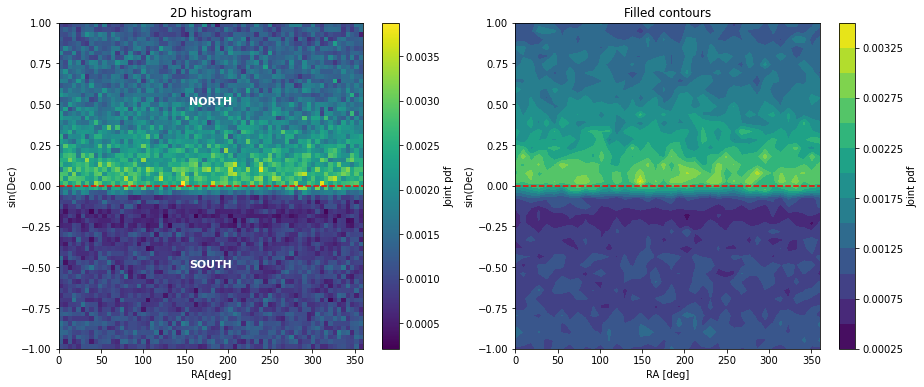

In [38]:
ra = df['RA'].values
sindec = np.sin(np.radians(df['Dec'].values))

fig, axes = plt.subplots(1, 2, figsize=(15,6))

# plot 1: 2D histogram which is density-normalized
ax = axes[0]
Nbins = 70
_,_,_,image = ax.hist2d(ra, sindec, bins=Nbins, range=[[0, 360], [-1,1 ]], density=True, cmap='viridis')
cbar = fig.colorbar(image, ax=ax, label='Joint pdf')
ax.axhline(0, color='red', ls='--', lw=1.5)
ax.text(180, 0.5, 'NORTH', color='white', ha='center', fontweight='bold', fontsize=11)
ax.text(180, -0.5, 'SOUTH', color='white', ha='center', fontweight='bold', fontsize=11)
ax.set_xlabel('RA[deg]')
ax.set_ylabel('sin(Dec)')
ax.set_title('2D histogram')

# plot 2: filled contours
ax = axes[1]
Nbins_c = 40
x = np.linspace(0, 360, Nbins_c)
y = np.linspace(-1, 1, Nbins_c)
X, Y = np.meshgrid(x, y)
z,_,_ = np.histogram2d(ra, sindec, bins=Nbins_c, range=[[0, 360], [-1,1]], density=True)
cs = ax.contourf(X, Y, z.T, levels=12, cmap='viridis')
cbar = fig.colorbar(cs, ax=ax, label='Joint pdf')
ax.axhline(0, color='red', ls='--', lw=1.5)
ax.set_xlabel('RA [deg]')
ax.set_ylabel('sin(Dec)')
ax.set_title('Filled contours')

This is the calculation of the correlation matrix of log10(E/GeV) and sin(dec) in the northern sky

Before we get into this, what is a correlation matrix? 
For two variables $X = \sin(\text{Dec})$ and $Y = \log_{10}(E/GeV)$, restricted to the northern-sky subsample, the covariance is
\begin{equation}
    \text{Cov}(X, Y) = \frac{1}{n-1} \sum_{i=1}^{n}(x_i - \overline{x})(y_i - \overline{y}) \notag
\end{equation}

and the Pearson correlation coefficient normalizes that by each variable's spread of
\begin{equation}
    \rho_{XY} = \frac{\text{Cov}(X,Y)}{\sigma_X \sigma_Y}, \quad -1 \leq \rho_{XY} \leq 1 \notag
\end{equation}

The full 2 $\times$ 2 correlation matrix just packages this symmetrically as
\begin{equation}
    R = \begin{pmatrix}
        \rho_{XX} \quad \rho_{XY} \\
        \rho_{YX} \quad  \rho_{YY}
        \end{pmatrix} = \begin{pmatrix}
                        1 \quad  \rho_{XY} \\
                        \rho_{XY} \quad 1 
                        \end{pmatrix} \notag
\end{equation}

In [42]:
sindec = np.sin(np.radians(df['Dec'].values))
logE = df['logE'].values

# restricting to the northern portion of the sky
north_mask = sindec > 0
sindec_n = sindec[north_mask]
logE_n = logE[north_mask]
print(f"Northern-sky events: n = {len(sindec_n)}")

# correlation matrix
corr_matrix = np.corrcoef(sindec_n, logE_n)
print("\nPearson correlation coefficient [[sindec-sindec, sindec-logE], [logE-sindec, logE-logE]]:")
print(corr_matrix)

rho = corr_matrix[0,1]
print(f"\nPearson correlation coefficient (sin(Dec), log10 E): rho = {rho:.4f}")

# checking the pieces
cov_manual = np.mean((sindec_n - sindec_n.mean()) * (logE_n - logE_n.mean()))
rho_manual = cov_manual / (sindec_n.std() * logE_n.std())
print(f"Manually-computed rho (population convention): {rho_manual:.4f}")

# binning logE as a function of sin(Dec)
bins = np.linspace(0, 1, 11)
bin_idx = np.digitize(sindec_n, bins) - 1
print("\nMean log10(E) vs sin(Dec) bin, within north:")
for b in range(10):
    sel = bin_idx == b
    if sel.sum() > 0:
        print(f" sin(Dec) in [{bins[b]:.1f}, {bins[b+1]:.1f}): mean logE = {logE_n[sel].mean():.3f} (n={sel.sum()})")

Northern-sky events: n = 83837

Pearson correlation coefficient [[sindec-sindec, sindec-logE], [logE-sindec, logE-logE]]:
[[ 1.         -0.14849017]
 [-0.14849017  1.        ]]

Pearson correlation coefficient (sin(Dec), log10 E): rho = -0.1485
Manually-computed rho (population convention): -0.1485

Mean log10(E) vs sin(Dec) bin, within north:
 sin(Dec) in [0.0, 0.1): mean logE = 3.032 (n=12356)
 sin(Dec) in [0.1, 0.2): mean logE = 3.016 (n=11362)
 sin(Dec) in [0.2, 0.3): mean logE = 3.001 (n=9887)
 sin(Dec) in [0.3, 0.4): mean logE = 2.995 (n=9069)
 sin(Dec) in [0.4, 0.5): mean logE = 2.985 (n=8289)
 sin(Dec) in [0.5, 0.6): mean logE = 2.989 (n=7394)
 sin(Dec) in [0.6, 0.7): mean logE = 2.981 (n=6782)
 sin(Dec) in [0.7, 0.8): mean logE = 2.970 (n=6708)
 sin(Dec) in [0.8, 0.9): mean logE = 2.945 (n=6279)
 sin(Dec) in [0.9, 1.0): mean logE = 2.878 (n=5711)


This is the same thing but for the southern sky

In [40]:
sindec = np.sin(np.radians(df['Dec'].values))
logE = df['logE'].values

# Restrict to the southern sky
south_mask = sindec < 0
sindec_s = sindec[south_mask]
logE_s = logE[south_mask]
print(f"Southern-sky events: n = {len(sindec_s)}")

# correlation matrix
corr_matrix = np.corrcoef(sindec_s, logE_s)
print("\nCorrelation matrix [[sindec-sindec, sindec-logE], [logE-sindec, logE-logE]]:")
print(corr_matrix)

rho = corr_matrix[0,1]
print(f"\nPearson correlation coefficient (sin(Dec), log10 E): rho = {rho:.4f}")

# binned mean logE vs sin(Dec)
bins = np.linspace(-1, 0, 11)
bin_idx = np.digitize(sindec_s, bins) - 1
print("\nMean log10(E) vs sin(Dec) bin, within south:")
for b in range(10):
    sel = bin_idx == b
    if sel.sum() > 0:
        print(f" sin(Dec) in [{bins[b]:.1f}, {bins[b+1]:.1f}): mean logE = {logE_s[sel].mean():.3f} (n={sel.sum()})")

Southern-sky events: n = 46001

Correlation matrix [[sindec-sindec, sindec-logE], [logE-sindec, logE-logE]]:
[[ 1.         -0.77706267]
 [-0.77706267  1.        ]]

Pearson correlation coefficient (sin(Dec), log10 E): rho = -0.7771

Mean log10(E) vs sin(Dec) bin, within south:
 sin(Dec) in [-1.0, -0.9): mean logE = 4.875 (n=4891)
 sin(Dec) in [-0.9, -0.8): mean logE = 5.103 (n=5163)
 sin(Dec) in [-0.8, -0.7): mean logE = 5.160 (n=4505)
 sin(Dec) in [-0.7, -0.6): mean logE = 5.125 (n=4338)
 sin(Dec) in [-0.6, -0.5): mean logE = 5.037 (n=4408)
 sin(Dec) in [-0.5, -0.4): mean logE = 4.908 (n=4498)
 sin(Dec) in [-0.4, -0.3): mean logE = 4.669 (n=3898)
 sin(Dec) in [-0.3, -0.2): mean logE = 4.336 (n=3706)
 sin(Dec) in [-0.2, -0.1): mean logE = 3.732 (n=3426)
 sin(Dec) in [-0.1, 0.0): mean logE = 3.074 (n=7168)


These are the two declinations that were chosen at random: (declination 1) and (declination 2), and the conditional PDF of log10(E/GeV) for the two declinations

Remember, we have to think about what a conditional PDF means in this context. The conditional PDF of energy is given a fixed declination of
\begin{equation}
    f(\log_{10} E | \text{Dec} = d) \notag
\end{equation}

Randomly chosen declinations: -20.34 deg, -50.50 deg
Dec = -20.34 deg: window +/-2.00 deg -> n = 2481 events,  mean logE = 4.672
Dec = -50.50 deg: window +/-2.00 deg -> n = 2077 events,  mean logE = 5.156


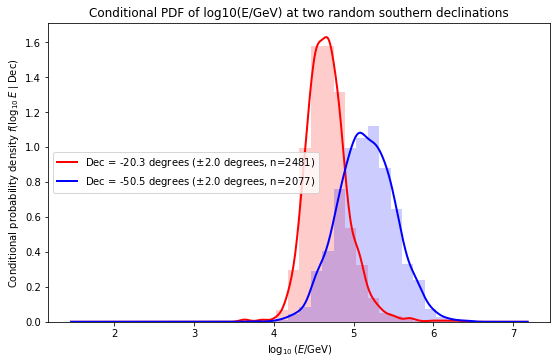

In [43]:
dec = df['Dec'].values
logE = df['logE'].values

# first choose two random declinations in the southern sky
rng = np.random.default_rng(42)
dec_choices = rng.uniform(-90, 0, size=2)
print(f"Randomly chosen declinations: {dec_choices[0]:.2f} deg, {dec_choices[1]:.2f} deg")

def get_slice(dec_center, half_width_init=2.0, min_n=500, max_half_width=15.0):
    hw = half_width_init
    while hw <= max_half_width:
        mask = (dec >= dec_center - hw) & (dec < dec_center + hw) & (dec < 0)
        if mask.sum() >= min_n:
            return logE[mask], hw, mask.sum()
        hw *= 1.5
    return logE[mask], hw, mask.sum()

fig, ax = plt.subplots(figsize=(9, 5.5))
colors = ['red', 'blue']

for dec_c, color in zip(dec_choices, colors):
    vals, hw, n = get_slice(dec_c)
    print(f"Dec = {dec_c:6.2f} deg: window +/-{hw:.2f} deg -> n = {n} events,  " 
            f"mean logE = {vals.mean():.3f}")

    # conditional PDF via kernel density estimation
    kde = gaussian_kde(vals)
    grid = np.linspace(logE.min(), logE.max(), 500)
    ax.plot(grid, kde(grid), color=color, lw=2, label=f'Dec = {dec_c:.1f} degrees ($\pm${hw:.1f} degrees, n={n})')
    ax.hist(vals, bins=40, range=(logE.min(), logE.max()), density=True, alpha=0.2, color=color)

ax.set_xlabel(r'$\log_{10}(E/\mathrm{GeV})$')
ax.set_ylabel(r'Conditional probability density $f(\log_{10}E \mid \mathrm{Dec})$')
ax.set_title('Conditional PDF of log10(E/GeV) at two random southern declinations')
ax.legend()

Now, this is for the joint PDF of events in the northern sky for AngErr vs log10(E/GeV). Since I don't know what the value for AngErr is, I went to go find that out first.

In [44]:
from matplotlib.colors import LogNorm

north = df[df['Dec'] > 0]
angerr = north['AngErr'].values
logE = north['logE'].values

print(f"Northern sky evnets: n = {len(north)}")
print(f"AngErr range: {angerr.min():.3f} to {angerr.max():.3f} deg")
print(f"AngErr: median={np.median(angerr):.3f}, mean={angerr.mean():.3f}")

Northern sky evnets: n = 83837
AngErr range: 0.200 to 28.310 deg
AngErr: median=0.790, mean=1.182


Okay, now that I know what the value for AngErr is, I can finish the rest of this problem.


Correlation matrix (logE, log10(AngErr)):
[[ 1.         -0.20691138]
 [-0.20691138  1.        ]]
rho = -0.2069
rho (logE, raw AngErr, unlogged) = -0.1510

Median AngErr vs log10(E) bin:
 logE in [1.46, 1.77]): median AngErr = 1.635 deg (n=36)
 logE in [1.77, 2.08]): median AngErr = 1.710 deg (n=90)
 logE in [2.08, 2.40]): median AngErr = 1.960 deg (n=365)
 logE in [2.40, 2.71]): median AngErr = 1.360 deg (n=5026)
 logE in [2.71, 3.02]): median AngErr = 0.800 deg (n=45609)
 logE in [3.02, 3.33]): median AngErr = 0.690 deg (n=26535)
 logE in [3.33, 3.64]): median AngErr = 0.650 deg (n=5164)
 logE in [3.64, 3.95]): median AngErr = 0.540 deg (n=818)
 logE in [3.95, 4.27]): median AngErr = 0.490 deg (n=151)
 logE in [4.27, 4.58]): median AngErr = 0.270 deg (n=35)


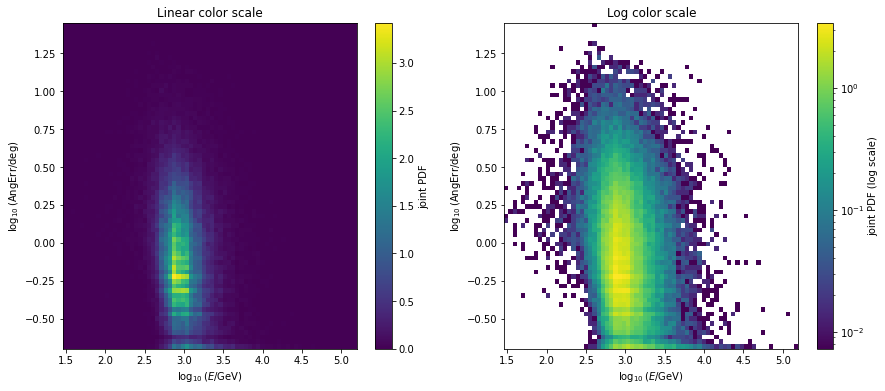

In [48]:
log_angerr = np.log10(angerr)

fig, axes = plt.subplots(1, 2, figsize=(14.5, 6))

# plot 1: 2D histogram, linear color
ax = axes[0]
Nbins = 70

_, _, _, image = ax.hist2d(logE, log_angerr, bins=Nbins, density=True, cmap='viridis')
cbar = fig.colorbar(image, ax=ax, label='joint PDF')
ax.set_xlabel(r'$\log_{10}(E/\mathrm{GeV})$')
ax.set_ylabel(r'$\log_{10}(\mathrm{AngErr}/\mathrm{deg})$')
ax.set_title('Linear color scale')

# plot 2: 2D histogram with log color
ax = axes[1]
_, _, _, image2 = ax.hist2d(logE, log_angerr, bins=Nbins, density=True, cmap='viridis', norm=LogNorm())
cbar = fig.colorbar(image2, ax=ax, label='joint PDF (log scale)')
ax.set_xlabel(r'$\log_{10}(E/\mathrm{GeV})$')
ax.set_ylabel(r'$\log_{10}(\mathrm{AngErr}/\mathrm{deg})$')
ax.set_title('Log color scale')

# correlation
corr_matrix = np.corrcoef(logE, log_angerr)
print(f"\nCorrelation matrix (logE, log10(AngErr)):\n{corr_matrix}")
print(f"rho = {corr_matrix[0,1]:.4f}")

# checking with AngErr directly
corr_raw = np.corrcoef(logE, angerr)[0,1]
print(f"rho (logE, raw AngErr, unlogged) = {corr_raw:.4f}")

# Binned median AngErr vs logE
bins = np.linspace(logE.min(), logE.max(), 13)
bin_idx = np.digitize(logE, bins) - 1
print("\nMedian AngErr vs log10(E) bin:")
for b in range(12):
    sel = bin_idx == b
    if sel.sum() > 20:
        print(f" logE in [{bins[b]:.2f}, {bins[b+1]:.2f}]): median AngErr = {np.median(angerr[sel]):.3f} deg (n={sel.sum()})")